# Guía de laboratorio 07 — Primalidad, grupos y algoritmos probabilísticos
**UNSAAC · Algoritmos Avanzados · 2026-II · Grupo 5**

**Integrantes:** Choquenaira Quispe, Noe Franklin (133962); Porroa Sivana, Yeni Ruth (120893); Quispe Rimachi, Romario (164257); Yaranga Achahui, Aldo (103179).

**Cuaderno autónomo:** ejecute **todas las celdas desde el inicio** en Colab o Jupyter con Python 3.11+. Cada ejercicio calcula y muestra su resultado debajo. **No usa `%%writefile`, archivos del repositorio, directorios temporales, `pip`, `pandas` ni `matplotlib`.** Las pruebas, CSV y cuatro gráficos SVG permanecen en memoria; la última celda permite descargar evidencias si las necesita.

## 1. Preparación y fundamentos
Se usa solamente Python 3.11+, su biblioteca estándar y la visualización propia del cuaderno. `random.Random` con semilla fija sirve para reproducir experimentos; la generación segura sin semilla usa `secrets.SystemRandom`. Fermat y Miller–Rabin pueden aceptar compuestos: superar rondas no demuestra primalidad. Para un compuesto impar, $r$ bases uniformes independientes dan cota de error $4^{-r}$.

In [1]:
import csv
import io
import json
import math
import secrets
import unittest
from collections import Counter
from html import escape
from random import Random
from statistics import mean, median
from time import perf_counter_ns
from unittest.mock import patch
from zipfile import ZIP_DEFLATED, ZipFile
from base64 import b64encode
from IPython.display import HTML, SVG, display
import sys

if sys.version_info < (3, 11):
    raise RuntimeError("Use Python 3.11 o posterior")

DATASETS = {}       # Filas CSV en memoria: nunca se escribe en disco.
CHARTS = {}         # SVG en memoria: cada figura aparece debajo de su celda.

def show_table(rows, columns=None, limit=30, title=None):
    rows = list(rows)
    if not rows:
        print("Tabla vacía")
        return
    columns = columns or list(rows[0])
    header = "".join(f"<th>{escape(str(k))}</th>" for k in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(row.get(k, '')))}</td>" for k in columns) + "</tr>"
        for row in rows[:limit]
    )
    caption = f"<b>{escape(title)}</b><br>" if title else ""
    display(HTML(caption + '<div style="overflow-x:auto;max-height:430px;overflow-y:auto">'
                 '<table style="border-collapse:collapse;font-size:13px" border="1" cellpadding="5">'
                 f"<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>"))
    if len(rows) > limit:
        print(f"Se muestran {limit} de {len(rows)} filas; el conjunto completo queda en memoria.")

def run_tests(*classes):
    suite = unittest.TestSuite(unittest.defaultTestLoader.loadTestsFromTestCase(cls)
                               for cls in classes)
    output = io.StringIO()
    result = unittest.TextTestRunner(stream=output, verbosity=1).run(suite)
    print(output.getvalue().strip())
    assert result.wasSuccessful(), "Fallaron pruebas; revise la salida anterior"

print(f"Entorno listo: Python {sys.version.split()[0]}; sin módulos ni archivos auxiliares.")

Entorno listo: Python 3.12.8; sin módulos ni archivos auxiliares.


## 8. Ejercicios resueltos: funciones y salidas junto a cada caso

### 8.1 División de prueba y Fermat
Una salida negativa demuestra composición. `341` pasa Fermat base 2 pese a ser compuesto.

In [2]:
"""Pruebas de primalidad y generación de probables primos (Guía 07, UNSAAC).

Una ronda de Miller--Rabin devuelve (pasa, detalle). El detalle incluye n, a,
s, d y, si trace=True, todos los residuos examinados. ``pasa`` NO certifica
primalidad; ``False`` sí certifica composición para n impar >= 5.

La fuente por defecto es secrets.SystemRandom; inyectar random.Random solo sirve
para ensayos reproducibles, nunca para generar claves criptográficas.
"""

import secrets
from math import gcd, isqrt

__all__ = [
    "trial_division", "trial_division_with_count", "fermat_round", "fermat_test",
    "decompose", "miller_rabin_round", "primality_report", "is_probable_prime",
    "generate_candidate", "generate_probable_prime", "classify_bases",
]


def _integer(*values):
    for value in values:
        if type(value) is not int:
            raise TypeError("Se esperaba un entero, no bool ni otro tipo")


def _primes_up_to(limit):
    sieve = bytearray(b"\x01") * (limit + 1)
    sieve[0:2] = b"\x00\x00"
    for p in range(2, isqrt(limit) + 1):
        if sieve[p]:
            sieve[p * p::p] = b"\x00" * len(sieve[p * p::p])
    return tuple(i for i in range(2, limit + 1) if sieve[i])


SMALL_PRIMES = _primes_up_to(997)


def trial_division_with_count(n):
    """Devuelve (es_primo, divisiones) con O(sqrt(n)) divisiones en el peor caso."""
    _integer(n)
    if n < 2:
        return False, 0
    if n in (2, 3):
        return True, 0
    if n % 2 == 0:
        return False, 1
    count = 1
    for divisor in range(3, isqrt(n) + 1, 2):
        count += 1
        if n % divisor == 0:
            return False, count
    return True, count


def trial_division(n):
    """Primalidad determinista por divisores impares hasta isqrt(n)."""
    return trial_division_with_count(n)[0]


def _mod_pow_counted(base, exponent, modulus):
    """Cuadrados sucesivos reales, no estimaciones de las operaciones de pow()."""
    result, base = 1 % modulus, base % modulus
    squares = products = 0
    while exponent:
        if exponent & 1:
            result = result * base % modulus
            products += 1
        exponent >>= 1
        if exponent:
            base = base * base % modulus
            squares += 1
    return result, squares, products


def _base(n, a):
    _integer(n, a)
    if n < 5 or n % 2 == 0:
        raise ValueError("La ronda requiere n impar >= 5")
    if not 2 <= a <= n - 2:
        raise ValueError("La base debe estar en [2, n-2]")


def fermat_round(n, a):
    """False demuestra composición; True solo dice que n pasa Fermat base a."""
    _base(n, a)
    if gcd(a, n) != 1:
        return False
    return _mod_pow_counted(a, n - 1, n)[0] == 1


def fermat_test(n, bases):
    """Fermat con bases configurables; ninguna cantidad de rondas da cota 4^-k."""
    _integer(n)
    bases = tuple(bases)
    if not bases:
        raise ValueError("Se requiere al menos una base")
    if n < 2:
        return {"resultado": "no_primo", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    if n in (2, 3):
        return {"resultado": "primo", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    if n % 2 == 0:
        return {"resultado": "compuesto", "rondas_ejecutadas": 0,
                "bases_ejecutadas": [], "cuadrados_modulares": 0}
    ran, squares, executed = 0, 0, []
    for a in bases:
        _base(n, a)
        executed.append(a)
        ran += 1
        if gcd(a, n) != 1:
            return {"resultado": "compuesto", "rondas_ejecutadas": ran,
                    "bases_ejecutadas": executed, "cuadrados_modulares": squares}
        residue, sq, _ = _mod_pow_counted(a, n - 1, n)
        squares += sq
        if residue != 1:
            return {"resultado": "compuesto", "rondas_ejecutadas": ran,
                    "bases_ejecutadas": executed, "cuadrados_modulares": squares}
    return {"resultado": "pasa_fermat", "rondas_ejecutadas": ran,
            "bases_ejecutadas": executed, "cuadrados_modulares": squares}

print('221 por división:', trial_division(221))
print('15 por Fermat base 2:', fermat_round(15, 2))
print('341 por Fermat base 2:', fermat_round(341, 2))

221 por división: False
15 por Fermat base 2: False
341 por Fermat base 2: True


In [3]:
def resuelto_1():
    """División de prueba y contraejemplo al recíproco de Fermat."""
    division_221 = trial_division(221)
    fermat_15 = fermat_round(15, 2)
    fermat_341 = fermat_round(341, 2)
    assert division_221 is False and fermat_15 is False and fermat_341 is True
    return {"221_es_primo": division_221, "15_pasa_fermat": fermat_15,
            "341_pasa_fermat": fermat_341}

show_table([resuelto_1()], title='Ejercicio resuelto 1: resultados')

221_es_primo,15_pasa_fermat,341_pasa_fermat
False,False,True


### 8.2 Miller–Rabin con traza
La ronda registra `n`, base, `s`, `d` y residuos en la misma celda.

In [4]:
def decompose(n):
    """n impar >= 3: devuelve (s,d) con n-1 = 2**s * d y d impar."""
    _integer(n)
    if n < 3 or n % 2 == 0:
        raise ValueError("n debe ser impar y >= 3")
    s, d = 0, n - 1
    while d % 2 == 0:
        s, d = s + 1, d // 2
    return s, d


def miller_rabin_round(n, a, trace=False):
    """Devuelve (pasa, detalle); el detalle registra n, a, s, d y residuos.

    ``cuadrados_modulares`` incluye exponentiación y cadena; ``cuadrados_cadena``
    cuenta solo la cadena. Se ejecuta el algoritmo binario instrumentado.
    """
    _base(n, a)
    s, d = decompose(n)
    x, squares, products = _mod_pow_counted(a, d, n)
    residues = [x] if trace else []
    chain_squares = 0
    passed = x in (1, n - 1)
    reason = "residuo_inicial" if passed else "sin_menos_uno"
    if not passed:
        for _ in range(s - 1):
            x = x * x % n
            chain_squares += 1
            if trace:
                residues.append(x)
            if x == n - 1:
                passed, reason = True, "aparece_menos_uno"
                break
            if x == 1:
                reason = "raiz_no_trivial_de_uno"
                break
    return passed, {
        "n": n, "a": a, "s": s, "d": d, "residuos": residues,
        "cuadrados_cadena": chain_squares,
        "cuadrados_modulares": squares + chain_squares,
        "productos_modulares": products, "motivo": reason,
    }

print('220 = 2^s · d:', decompose(221))
pasa, detalle = miller_rabin_round(221, 2, trace=True)
show_table([{'pasa': pasa, **detalle}], title='Miller–Rabin: n=221, base=2')

220 = 2^s · d: (2, 55)


pasa,n,a,s,d,residuos,cuadrados_cadena,cuadrados_modulares,productos_modulares,motivo
False,221,2,2,55,"[128, 30]",1,6,5,sin_menos_uno


In [5]:
def resuelto_2():
    """Traza verificable de Miller--Rabin para n=221, base a=2."""
    assert decompose(221) == (2, 55)
    passed, detail = miller_rabin_round(221, 2, trace=True)
    assert not passed and detail["residuos"] == [128, 30]
    assert (detail["n"], detail["a"], detail["s"], detail["d"]) == (221, 2, 2, 55)
    return {"pasa": passed, **detail}

show_table([resuelto_2()], title='Ejercicio resuelto 2: traza verificada')

pasa,n,a,s,d,residuos,cuadrados_cadena,cuadrados_modulares,productos_modulares,motivo
False,221,2,2,55,"[128, 30]",1,6,5,sin_menos_uno


### 8.3 Rondas repetidas, candidatos y precribado
La semilla fija solo reproduce los experimentos. Sin semilla, la biblioteca usa una fuente segura del sistema.

In [6]:
def _presieve_divisor(n):
    for p in SMALL_PRIMES:
        if n % p == 0:
            return p
    return None


def primality_report(n, rounds=20, rng=None, *, bases=None, presieve=True):
    """Resultado auditable. Cota 4^-r solo para probable primo tras r rondas.

    Las bases suministradas permiten comparar métodos sobre entradas idénticas.
    La cota asume bases uniformes independientes; con bases fijas es solo una
    referencia teórica, no una garantía para esa ejecución concreta.
    """
    _integer(n, rounds)
    if rounds < 1:
        raise ValueError("rounds debe ser >= 1")
    report = {"n": n, "resultado": "no_primo", "rondas_solicitadas": rounds,
              "rondas_ejecutadas": 0, "bases_ejecutadas": [],
              "cuadrados_modulares": 0, "cuadrados_cadena": 0,
              "descartado_precribado": False, "cota_error": 0.0}
    if n < 2:
        return report
    if n in (2, 3):
        report["resultado"] = "primo"
        return report
    if n % 2 == 0:
        report["resultado"] = "compuesto"
        report["descartado_precribado"] = True
        return report
    if presieve:
        if n in SMALL_PRIMES:
            report["resultado"] = "primo"
            return report
        if _presieve_divisor(n) is not None:
            report["resultado"] = "compuesto"
            report["descartado_precribado"] = True
            return report
    if bases is not None:
        bases = tuple(bases)
        if len(bases) < rounds:
            raise ValueError("Faltan bases para las rondas solicitadas")
        chosen = bases[:rounds]
    else:
        generator = rng if rng is not None else secrets.SystemRandom()
        chosen = (generator.randrange(2, n - 1) for _ in range(rounds))
    for a in chosen:
        passed, detail = miller_rabin_round(n, a)
        report["rondas_ejecutadas"] += 1
        report["bases_ejecutadas"].append(a)
        report["cuadrados_modulares"] += detail["cuadrados_modulares"]
        report["cuadrados_cadena"] += detail["cuadrados_cadena"]
        if not passed:
            report["resultado"] = "compuesto"
            return report
    report["resultado"] = "probable_primo"
    report["cota_error"] = 4.0 ** (-rounds)
    return report


def is_probable_prime(n, rounds=20, rng=None):
    """Interfaz booleana de la guía. Para rondas/cota use primality_report()."""
    return primality_report(n, rounds, rng)["resultado"] in ("primo", "probable_primo")

show_table([primality_report(1009, rounds=5, rng=Random(2026))],
           title='Cinco rondas y cota de error')

n,resultado,rondas_solicitadas,rondas_ejecutadas,bases_ejecutadas,cuadrados_modulares,cuadrados_cadena,descartado_precribado,cota_error
1009,probable_primo,5,5,"[123, 329, 516, 976, 526]",39,14,False,0.0009765625


In [7]:
def generate_candidate(bits, rng=None):
    """Candidato impar de exactamente bits bits; RNG seguro si no se especifica."""
    _integer(bits)
    if bits < 2:
        raise ValueError("bits debe ser >= 2")
    generator = rng if rng is not None else secrets.SystemRandom()
    return generator.getrandbits(bits) | (1 << (bits - 1)) | 1


def generate_probable_prime(bits, rounds=20, rng=None, *, return_report=False):
    """Muestreo de candidatos hasta obtener un probable primo de bits bits.

    Devuelve n por defecto; con return_report=True devuelve n y conteos reales.
    random.Random es SOLO para experimentos; sin rng utiliza SystemRandom.
    """
    _integer(bits, rounds)
    if bits < 2 or rounds < 1:
        raise ValueError("bits >= 2 y rounds >= 1 son obligatorios")
    generator = rng if rng is not None else secrets.SystemRandom()
    attempts = discarded = executed = squares = 0
    while True:
        n = generate_candidate(bits, generator)
        attempts += 1
        result = primality_report(n, rounds, generator)
        discarded += int(result["descartado_precribado"])
        executed += result["rondas_ejecutadas"]
        squares += result["cuadrados_modulares"]
        if result["resultado"] in ("primo", "probable_primo"):
            if return_report:
                return {"n": n, "bits": bits, "candidatos": attempts,
                        "descartes_precribado": discarded, "rondas_ejecutadas": executed,
                        "cuadrados_modulares": squares, "rondas_finales": result["rondas_ejecutadas"],
                        "cota_error": result["cota_error"]}
            return n


def classify_bases(n):
    """Enumera todas las bases de un compuesto impar pequeño (costo O(n))."""
    _integer(n)
    if n < 5 or n % 2 == 0 or trial_division(n):
        raise ValueError("Se requiere un compuesto impar >= 5")
    liars, witnesses = [], []
    for a in range(2, n - 1):
        passed, _ = miller_rabin_round(n, a)
        (liars if passed else witnesses).append(a)
    return {"n": n, "mentirosos_fuertes": liars, "testigos": witnesses,
            "fraccion_mentirosos": len(liars) / (n - 3)}

candidato = generate_candidate(32, Random(2026))
print('Candidato de 32 bits:', candidato, '| bits:', candidato.bit_length(), '| impar:', bool(candidato % 2))

Candidato de 32 bits: 2659099673 | bits: 32 | impar: True


In [8]:
def resuelto_3():
    """Candidato reproducible y cinco rondas sobre el primo conocido 1009."""
    rng = Random(2026)
    n = generate_candidate(32, rng)
    assert n.bit_length() == 32 and n % 2 == 1
    report = primality_report(1009, rounds=5, rng=Random(2026))
    assert report["resultado"] == "probable_primo"
    assert report["rondas_ejecutadas"] == 5 and report["cota_error"] == 4.0**-5
    return {"candidato": n, "bits": n.bit_length(), "impar": bool(n % 2),
            "1009_resultado": report["resultado"],
            "rondas_ejecutadas": report["rondas_ejecutadas"],
            "cota_error": report["cota_error"]}

show_table([resuelto_3()], title='Ejercicio resuelto 3: candidato y rondas')

candidato,bits,impar,1009_resultado,rondas_ejecutadas,cota_error
2659099673,32,True,probable_primo,5,0.0009765625


## 9.1 Biblioteca integrada y validación
Todas las funciones anteriores viven en este cuaderno. No se importan módulos escritos en otro lugar.

In [9]:
"""Casos reproducibles de laboratorio; random.Random NO sirve para claves."""

from random import Random


SEED = 202607
SIZES = (16, 32, 64, 128, 256, 512, 1024)
KNOWN_CASES = (
    (0, False), (1, False), (2, True), (3, True), (4, False),
    (5, True), (7, True), (9, False), (25, False), (49, False),
    (97, True), (221, False), (341, False), (561, False),
    (1105, False), (1729, False),
)


def make_rng(seed=SEED):
    return Random(seed)


def random_composite(bits, rng):
    """Producto impar de dos factores > 1, exactamente bits bits.

    A diferencia de una etiqueta probabilística, este constructor garantiza
    composición; no presupone que los factores sean primos.
    """
    if bits < 4:
        raise ValueError("bits debe ser >= 4")
    left = bits // 2
    right = bits - left
    while True:
        a = generate_candidate(left, rng)
        b = generate_candidate(right, rng)
        n = a * b
        if n.bit_length() == bits:
            return n


def benchmark_inputs(bits, primes, rng, count=8):
    """Pares equilibrados probable primo/compuesto; bases compartidas."""
    cases = []
    for i in range(count):
        prime_label = "primo_verificado" if bits <= 32 else "probable_primo"
        for kind, n in ((prime_label, primes[i]),
                        ("compuesto_construido", random_composite(bits, rng))):
            bases = tuple(rng.randrange(2, n - 1) for _ in range(20))
            cases.append({"bits": bits, "tipo": kind, "n": n,
                          "bases": bases, "indice": i})
    return cases

print('Semilla de pruebas:', SEED, '| tamaños:', SIZES)
print('Ejemplo de compuesto garantizado de 16 bits:', random_composite(16, make_rng()))

Semilla de pruebas: 202607 | tamaños: (16, 32, 64, 128, 256, 512, 1024)
Ejemplo de compuesto garantizado de 16 bits: 62985


### Pruebas: División de prueba
La misma celda define y ejecuta su conjunto; el resultado aparece justo debajo.

In [10]:
"""Suite unittest de la Guía 07; sin dependencias externas."""

import math
import unittest
from random import Random
from unittest.mock import patch



class TestDivision(unittest.TestCase):
    def test_casos_conocidos(self):
        for n, expected in KNOWN_CASES:
            with self.subTest(n=n):
                self.assertEqual(trial_division(n), expected)

    def test_oraculo_independiente(self):
        # Criba independiente de la función bajo prueba.
        sieve = bytearray(b"\x01") * 10_001
        sieve[:2] = b"\x00\x00"
        for p in range(2, math.isqrt(10_000) + 1):
            if sieve[p]:
                sieve[p * p::p] = b"\x00" * len(sieve[p * p::p])
        for n in range(10_001):
            self.assertEqual(trial_division(n), bool(sieve[n]))

    def test_cuadrados_de_primos(self):
        for p in (3, 5, 7, 11, 97, 997):
            self.assertFalse(trial_division(p * p))

    def test_cuenta_divisiones(self):
        self.assertEqual(trial_division_with_count(2), (True, 0))
        self.assertEqual(trial_division_with_count(9), (False, 2))
        self.assertEqual(trial_division_with_count(97)[0], True)

    def test_tipos_invalidos(self):
        for n in (True, 2.5, "7"):
            with self.assertRaises(TypeError):
                trial_division(n)

run_tests(TestDivision)

.....
----------------------------------------------------------------------
Ran 5 tests in 0.030s

OK


### Pruebas: Fermat
La misma celda define y ejecuta su conjunto; el resultado aparece justo debajo.

In [11]:
class TestFermat(unittest.TestCase):
    def test_aserciones_guia(self):
        self.assertFalse(fermat_round(15, 2))
        self.assertTrue(fermat_round(341, 2))

    def test_carmichael_y_base_no_coprima(self):
        for n in (561, 1105, 1729):
            self.assertTrue(fermat_round(n, 2))
        self.assertFalse(fermat_round(561, 3))

    def test_fallo_implica_compuesto(self):
        for n in range(5, 201, 2):
            for a in range(2, n - 1):
                if not fermat_round(n, a):
                    self.assertFalse(trial_division(n))

    def test_bases_configurables(self):
        self.assertEqual(fermat_test(341, [2])["resultado"], "pasa_fermat")
        self.assertEqual(fermat_test(561, [2, 3])["resultado"], "compuesto")
        self.assertEqual(fermat_test(1, [2])["resultado"], "no_primo")
        self.assertEqual(fermat_test(3, [2])["resultado"], "primo")

    def test_bases_invalidas(self):
        for n, a in ((3, 2), (9, 1), (9, 8), (10, 2)):
            with self.assertRaises(ValueError):
                fermat_round(n, a)
        with self.assertRaises(ValueError):
            fermat_test(341, [])

run_tests(TestFermat)

.....
----------------------------------------------------------------------
Ran 5 tests in 0.047s

OK


### Pruebas: Miller–Rabin y trazas
La misma celda define y ejecuta su conjunto; el resultado aparece justo debajo.

In [12]:
class TestMillerRabin(unittest.TestCase):
    def test_descomposicion_y_precondiciones(self):
        for n in range(3, 301, 2):
            s, d = decompose(n)
            self.assertGreaterEqual(s, 1)
            self.assertEqual(d % 2, 1)
            self.assertEqual(n - 1, 2**s * d)
        for n in (0, 1, 2, 4, -1):
            with self.assertRaises(ValueError):
                decompose(n)

    def test_trazas_obligatorias(self):
        traces = {
            221: (2, 55, [128, 30]),
            341: (2, 85, [32, 1]),
            561: (4, 35, [263, 166, 67, 1]),
        }
        for n, (s, d, residues) in traces.items():
            passed, detail = miller_rabin_round(n, 2, trace=True)
            self.assertFalse(passed)
            self.assertEqual((detail["n"], detail["a"], detail["s"], detail["d"]),
                             (n, 2, s, d))
            self.assertEqual(detail["residuos"], residues)

    def test_mr_detecta_carmichael_base_dos(self):
        for n in (561, 1105, 1729):
            self.assertFalse(miller_rabin_round(n, 2)[0])

    def test_raiz_no_trivial(self):
        _, detail = miller_rabin_round(341, 2, True)
        self.assertEqual(detail["motivo"], "raiz_no_trivial_de_uno")
        self.assertEqual(math.gcd(32 - 1, 341), 31)
        self.assertEqual(math.gcd(32 + 1, 341), 11)

    def test_conteo_real_de_cuadrados(self):
        _, detail = miller_rabin_round(221, 2, True)
        self.assertEqual(detail["cuadrados_modulares"], 6)
        self.assertEqual(detail["cuadrados_cadena"], 1)
        self.assertEqual(detail["productos_modulares"], (55).bit_count())

    def test_todos_los_primos_pequenos_y_bases(self):
        for n in range(5, 151, 2):
            if trial_division(n):
                for a in range(2, n - 1):
                    self.assertTrue(miller_rabin_round(n, a)[0], (n, a))

    def test_fallo_implica_compuesto(self):
        for n in range(5, 151, 2):
            for a in range(2, n - 1):
                if not miller_rabin_round(n, a)[0]:
                    self.assertFalse(trial_division(n))

    def test_testigo_y_mentiroso_fuerte(self):
        result = classify_bases(25)
        self.assertIn(7, result["mentirosos_fuertes"])
        self.assertIn(2, result["testigos"])
        self.assertEqual(len(result["mentirosos_fuertes"]) + len(result["testigos"]), 22)
        self.assertLessEqual(result["fraccion_mentirosos"], 0.25)

    def test_clasificacion_invalida(self):
        for n in (1, 2, 4, 7):
            with self.assertRaises(ValueError):
                classify_bases(n)

    def test_bases_extremas(self):
        self.assertTrue(miller_rabin_round(97, 2)[0])
        self.assertTrue(miller_rabin_round(97, 95)[0])
        for a in (1, 96):
            with self.assertRaises(ValueError):
                miller_rabin_round(97, a)

    def test_sin_traza(self):
        passed, detail = miller_rabin_round(97, 2)
        self.assertTrue(passed)
        self.assertEqual(detail["residuos"], [])
        self.assertEqual((detail["n"], detail["a"]), (97, 2))

run_tests(TestMillerRabin)

...........
----------------------------------------------------------------------
Ran 11 tests in 0.055s

OK

### Pruebas: Rondas, cotas y 1000 aleatorios
La misma celda define y ejecuta su conjunto; el resultado aparece justo debajo.

In [13]:
class TestPruebasRepetidas(unittest.TestCase):
    def test_mil_aleatorios_menores_de_un_millon(self):
        rng = make_rng(707)
        bases_rng = make_rng(1707)
        for _ in range(1000):
            n = rng.randrange(1_000_000)
            self.assertEqual(is_probable_prime(n, 20, bases_rng), trial_division(n), n)

    def test_bordes_y_cota(self):
        for n, expected in KNOWN_CASES:
            report = primality_report(n, 20, make_rng(7))
            self.assertEqual(report["resultado"] in ("primo", "probable_primo"), expected, n)
        report = primality_report(1009, 20, bases=[2] * 20)
        self.assertEqual(report["resultado"], "probable_primo")
        self.assertEqual(report["rondas_ejecutadas"], 20)
        self.assertEqual(report["cota_error"], 4.0**-20)

    def test_base_testigo_y_rechazo_temprano(self):
        report = primality_report(341, 20, bases=[2] * 20, presieve=False)
        self.assertEqual(report["resultado"], "compuesto")
        self.assertEqual(report["rondas_ejecutadas"], 1)
        self.assertEqual(report["cota_error"], 0)

    def test_cotas_para_cuatro_configuraciones(self):
        for rounds in (1, 5, 10, 20):
            result = primality_report(1009, rounds, bases=[2] * rounds)
            self.assertEqual(result["cota_error"], 4.0**-rounds)

    def test_reproducibilidad_y_precribado(self):
        r1 = primality_report(1009, 20, make_rng(26))
        r2 = primality_report(1009, 20, make_rng(26))
        self.assertEqual(r1, r2)
        discarded = primality_report(561, 20, make_rng(26))
        self.assertTrue(discarded["descartado_precribado"])
        self.assertEqual(discarded["rondas_ejecutadas"], 0)

    def test_rondas_y_bases_invalidas(self):
        for rounds in (0, -1):
            with self.assertRaises(ValueError):
                is_probable_prime(97, rounds)
        with self.assertRaises(ValueError):
            primality_report(1009, 5, bases=[2, 3])
        with self.assertRaises(ValueError):
            primality_report(1009, 1, bases=[1])

run_tests(TestPruebasRepetidas)

......
----------------------------------------------------------------------
Ran 6 tests in 0.051s

OK


### Pruebas: Generación de 16 a 1024 bits
La misma celda define y ejecuta su conjunto; el resultado aparece justo debajo.

In [14]:
class TestGeneracion(unittest.TestCase):
    def test_candidatos_16_a_1024_bits(self):
        rng = make_rng(2026)
        for bits in SIZES:
            for _ in range(50):
                n = generate_candidate(bits, rng)
                self.assertEqual(n.bit_length(), bits)
                self.assertEqual(n % 2, 1)

    def test_minimo_y_tipos(self):
        self.assertEqual(generate_candidate(2, make_rng(1)), 3)
        for bits in (0, 1, -1):
            with self.assertRaises(ValueError):
                generate_candidate(bits)
        with self.assertRaises(TypeError):
            generate_candidate(True)

    def test_generacion_reproducible(self):
        for bits in (16, 64, 128):
            a = generate_probable_prime(bits, 10, make_rng(123), return_report=True)
            b = generate_probable_prime(bits, 10, make_rng(123), return_report=True)
            self.assertEqual(a, b)
            self.assertEqual(a["n"].bit_length(), bits)
            self.assertEqual(a["n"] % 2, 1)
            self.assertTrue(is_probable_prime(a["n"], 20, make_rng(8)))
            self.assertLessEqual(a["descartes_precribado"], a["candidatos"] - 1)

    def test_generacion_segura_por_defecto(self):
        with patch.object(secrets, "SystemRandom", return_value=make_rng(7)) as secure:
            n = generate_probable_prime(16, rounds=5)
            self.assertEqual(n.bit_length(), 16)
            secure.assert_called_once()
        with patch.object(secrets, "SystemRandom", return_value=make_rng(8)) as secure:
            n = generate_candidate(32)
            self.assertEqual(n.bit_length(), 32)
            secure.assert_called_once()

    def test_compuestos_garantizados(self):
        rng = make_rng(12345)
        for bits in SIZES:
            n = random_composite(bits, rng)
            self.assertEqual(n.bit_length(), bits)
            self.assertFalse(is_probable_prime(n, 20, make_rng(5)))

run_tests(TestGeneracion)

.....
----------------------------------------------------------------------
Ran 5 tests in 0.027s

OK

### Testigos y mentirosos fuertes: clasificación visible
`25` es compuesto; algunas bases lo aceptan. La clasificación exhaustiva permanece en memoria.

In [15]:
c25 = classify_bases(25)
show_table([{"n": 25, "base": a, "clasificación":
             "mentiroso fuerte" if a in c25["mentirosos_fuertes"] else "testigo"}
            for a in range(2, 24)], title="Todas las bases válidas de 25", limit=30)
print("Total de testigos:", len(c25["testigos"]),
      "| mentirosos fuertes:", len(c25["mentirosos_fuertes"]))

n,base,clasificación
25,2,testigo
25,3,testigo
25,4,testigo
25,5,testigo
25,6,testigo
25,7,mentiroso fuerte
25,8,testigo
25,9,testigo
25,10,testigo
25,11,testigo


Total de testigos: 20 | mentirosos fuertes: 2


## 9.2 Comparación experimental
Entradas y bases preparadas antes de medir. Se emplean siete repeticiones por caso sin impresión durante la ventana cronometrada. Semillas: `20260701` (generación), `20260702` (comparación) y `20260703` (clasificación). División de prueba solo hasta 32 bits. Todos los datos quedan en `DATASETS`, no en carpetas.

### 11. Casos conocidos y trazas
Estos resultados se calculan y muestran en esta misma celda.

In [16]:
from statistics import mean, median
from time import perf_counter_ns

SEED_GENERATION, SEED_BENCHMARK, SEED_LIARS = 20260701, 20260702, 20260703
ROUNDS = (1, 5, 10, 20)
PRIMES_PER_BITS = 30
BENCHMARK_PAIRS = 8
REPETITIONS = 7
TRIAL_MAX_BITS = 32

def measure(function, repetitions=REPETITIONS):
    """Mínimo, mediana y máximo en ns; sin impresión, CSV ni RNG en la ventana."""
    times = []
    for _ in range(repetitions):
        start = perf_counter_ns()
        function()
        times.append(perf_counter_ns() - start)
    return min(times), median(times), max(times)

def write_csv(name, rows):
    """Almacena filas CSV en memoria; el último bloque ofrece su descarga."""
    DATASETS[name] = list(rows)
    if not DATASETS[name]:
        raise ValueError(f"Sin filas: {name}")

def known_and_traces():
    cases = []
    for n, actual_prime in KNOWN_CASES:
        fm = fermat_round(n, 2) if n >= 5 and n % 2 else "no_aplica"
        mr = miller_rabin_round(n, 2)[0] if n >= 5 and n % 2 else "no_aplica"
        cases.append({"n": n, "clasificacion": "primo" if actual_prime else
                      ("no_primo_ni_compuesto" if n < 2 else "compuesto"),
                      "division_prueba": trial_division(n), "fermat_base_2": fm,
                      "miller_rabin_base_2": mr,
                      "precribado": primality_report(n)["descartado_precribado"]})
    write_csv("casos_conocidos.csv", cases)

    traces = []
    for n, a in ((221, 2), (341, 2), (561, 2), (1105, 2), (1729, 2), (25, 7)):
        passed, row = miller_rabin_round(n, a, trace=True)
        traces.append({"n": n, "a": a, "s": row["s"], "d": row["d"],
                       "residuos": json.dumps(row["residuos"]),
                       "pasa": passed, "motivo": row["motivo"],
                       "cuadrados_modulares": row["cuadrados_modulares"]})
    write_csv("trazas_miller_rabin.csv", traces)
    return cases, traces

casos, trazas = known_and_traces()
show_table(casos, title="Casos conocidos: división, Fermat y Miller–Rabin")
show_table([row for row in trazas if row["n"] in (221, 341, 561)],
           title="Trazas obligatorias, base 2")

n,clasificacion,division_prueba,fermat_base_2,miller_rabin_base_2,precribado
0,no_primo_ni_compuesto,False,no_aplica,no_aplica,False
1,no_primo_ni_compuesto,False,no_aplica,no_aplica,False
2,primo,True,no_aplica,no_aplica,False
3,primo,True,no_aplica,no_aplica,False
4,compuesto,False,no_aplica,no_aplica,True
5,primo,True,True,True,False
7,primo,True,True,True,False
9,compuesto,False,False,False,True
25,compuesto,False,False,False,True
49,compuesto,False,False,False,True


n,a,s,d,residuos,pasa,motivo,cuadrados_modulares
221,2,2,55,"[128, 30]",False,sin_menos_uno,6
341,2,2,85,"[32, 1]",False,raiz_no_trivial_de_uno,7
561,2,4,35,"[263, 166, 67, 1]",False,raiz_no_trivial_de_uno,8


### 11. Generación de 30 probables primos por tamaño
Total: 210. Los de 16 y 32 bits también se verifican exactamente; los mayores siguen siendo *probables primos*.

In [17]:
def generate_primes():
    rng = make_rng(SEED_GENERATION)
    rows, primes_by_bits, summary = [], {}, []
    for bits in SIZES:
        primes = []
        for index in range(PRIMES_PER_BITS):
            start = perf_counter_ns()
            result = generate_probable_prime(bits, rounds=20, rng=rng, return_report=True)
            elapsed = perf_counter_ns() - start
            n = result["n"]
            assert n.bit_length() == bits and n % 2 == 1
            if bits <= TRIAL_MAX_BITS:
                assert trial_division(n), n
            primes.append(n)
            rows.append({"seed": SEED_GENERATION, "bits": bits, "indice": index,
                         "n": n, "resultado": "primo_verificado" if bits <= 32
                         else "probable_primo", "candidatos": result["candidatos"],
                         "descartes_precribado": result["descartes_precribado"],
                         "rondas_ejecutadas": result["rondas_ejecutadas"],
                         "cuadrados_modulares": result["cuadrados_modulares"],
                         "rondas_finales": result["rondas_finales"],
                         "cota_error": result["cota_error"],
                         "verificacion_exacta": bits <= TRIAL_MAX_BITS,
                         "tiempo_generacion_ns": elapsed})
        primes_by_bits[bits] = primes
        group = [r for r in rows if r["bits"] == bits]
        summary.append({"seed": SEED_GENERATION, "bits": bits,
                        "primos_probables": len(group),
                        "candidatos_total": sum(r["candidatos"] for r in group),
                        "candidatos_media": round(mean(r["candidatos"] for r in group), 2),
                        "candidatos_mediana": median(r["candidatos"] for r in group),
                        "candidatos_min": min(r["candidatos"] for r in group),
                        "candidatos_max": max(r["candidatos"] for r in group),
                        "descartes_precribado": sum(r["descartes_precribado"] for r in group),
                        "rondas_ejecutadas": sum(r["rondas_ejecutadas"] for r in group),
                        "cuadrados_modulares": sum(r["cuadrados_modulares"] for r in group),
                        "tiempo_mediano_ms": round(median(r["tiempo_generacion_ns"]
                                                       for r in group) / 1e6, 3),
                        "tiempo_min_ms": round(min(r["tiempo_generacion_ns"]
                                                    for r in group) / 1e6, 3),
                        "tiempo_max_ms": round(max(r["tiempo_generacion_ns"]
                                                    for r in group) / 1e6, 3),
                        "candidatos_estimados": round(bits * math.log(2) / 2, 1)})
        print(f"Generación {bits:4d} bits: {len(group)} probables primos, "
              f"{summary[-1]['candidatos_total']} candidatos")
    write_csv("generacion_210_probables_primos.csv", rows)
    write_csv("resumen_generacion.csv", summary)
    return primes_by_bits, summary

primes_by_bits, generation = generate_primes()
show_table(generation, columns=["bits", "primos_probables", "candidatos_total",
                               "candidatos_media", "candidatos_mediana",
                               "descartes_precribado", "rondas_ejecutadas",
                               "cuadrados_modulares", "tiempo_min_ms",
                               "tiempo_mediano_ms", "tiempo_max_ms"],
           title="Generación reproducible: resumen por tamaño")

Generación   16 bits: 30 probables primos, 169 candidatos


Generación   32 bits: 30 probables primos, 371 candidatos


Generación   64 bits: 30 probables primos, 652 candidatos
Generación  128 bits: 30 probables primos, 970 candidatos


Generación  256 bits: 30 probables primos, 1840 candidatos


Generación  512 bits: 30 probables primos, 5307 candidatos


Generación 1024 bits: 30 probables primos, 12870 candidatos


bits,primos_probables,candidatos_total,candidatos_media,candidatos_mediana,descartes_precribado,rondas_ejecutadas,cuadrados_modulares,tiempo_min_ms,tiempo_mediano_ms,tiempo_max_ms
16,30,169,5.63,5.0,139,600,8192,0.178,0.296,3.396
32,30,371,12.37,10.5,310,631,18712,0.501,0.971,1.648
64,30,652,21.73,16.5,537,685,42207,0.992,1.916,5.336
128,30,970,32.33,22.5,806,734,92300,2.639,4.387,7.952
256,30,1840,61.33,40.5,1541,869,220545,10.901,15.601,50.437
512,30,5307,176.9,97.5,4445,1432,730111,44.317,81.291,388.551
1024,30,12870,429,314.5,10833,2607,2664123,284.337,882.006,4532.673


### Visualización inline, sin librerías gráficas
Los gráficos son SVG creados en memoria. Se verán debajo de las celdas correspondientes.

In [18]:
def line_chart(filename, title, x_values, series, xlabel, ylabel, log_y=False, note=""):
    """Gráfico SVG construido en memoria; sin matplotlib, archivos ni instalación."""
    width, height = 940, 510
    left, right, top, bottom = 95, 730, 55, 425
    colors = ("#2165ae", "#de641e", "#198761", "#684ca8", "#aa3981")
    positive = [y for _, points in series for _, y in points if y > 0]
    if not positive:
        raise ValueError("La gráfica necesita al menos un dato positivo")
    y_min = min(positive) if log_y else min(0, min(positive))
    y_max = max(positive)
    if log_y:
        y_min, y_max = math.floor(math.log10(y_min)), math.ceil(math.log10(y_max))
        if y_max == y_min:
            y_max += 1
    elif y_max == y_min:
        y_max += 1

    def xx(x):
        return left + (right - left) * x_values.index(x) / max(1, len(x_values) - 1)

    def yy(y):
        value = math.log10(y) if log_y else y
        return bottom - (bottom - top) * (value - y_min) / (y_max - y_min)

    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
             '<rect width="100%" height="100%" fill="white"/>',
             f'<text x="{left}" y="27" font-size="19" font-family="Arial" font-weight="bold">{escape(title)}</text>',
             f'<line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#333"/>',
             f'<line x1="{left}" y1="{top}" x2="{left}" y2="{bottom}" stroke="#333"/>']
    for x in x_values:
        px = xx(x)
        parts += [f'<line x1="{px}" y1="{bottom}" x2="{px}" y2="{bottom + 5}" stroke="#333"/>',
                  f'<text x="{px}" y="{bottom + 23}" text-anchor="middle" font-size="12" font-family="Arial">{x}</text>']
    for i in range(6):
        fraction = i / 5
        value = y_min + fraction * (y_max - y_min)
        display_value = 10**value if log_y else value
        py = bottom - fraction * (bottom - top)
        parts += [f'<line x1="{left}" y1="{py}" x2="{right}" y2="{py}" stroke="#e4e4e4"/>',
                  f'<text x="{left - 8}" y="{py + 4}" text-anchor="end" font-size="11" font-family="Arial">{display_value:.2g}</text>']
    parts += [f'<text x="{(left + right) / 2}" y="{height - 23}" text-anchor="middle" font-size="13" font-family="Arial">{escape(xlabel)}</text>',
              f'<text transform="translate(20 {(top + bottom) / 2}) rotate(-90)" text-anchor="middle" font-size="13" font-family="Arial">{escape(ylabel)}</text>']
    for i, (label, points) in enumerate(series):
        color = colors[i % len(colors)]
        visible = [(x, y) for x, y in points if y > 0 or not log_y]
        coords = " ".join(f"{xx(x):.1f},{yy(y):.1f}" for x, y in visible)
        if coords:
            parts.append(f'<polyline points="{coords}" fill="none" stroke="{color}" stroke-width="2.5"/>')
        for x, y in visible:
            parts.append(f'<circle cx="{xx(x):.1f}" cy="{yy(y):.1f}" r="4" fill="{color}"/>')
        ly = 80 + i * 25
        parts += [f'<line x1="{right + 18}" y1="{ly}" x2="{right + 38}" y2="{ly}" stroke="{color}" stroke-width="3"/>',
                  f'<text x="{right + 45}" y="{ly + 4}" font-size="11" font-family="Arial">{escape(label)}</text>']
    if note:
        parts.append(f'<text x="{left}" y="{height - 5}" font-size="11" font-family="Arial">{escape(note)}</text>')
    parts.append('</svg>')
    svg = "".join(parts)
    CHARTS[filename] = svg
    display(SVG(data=svg))
    return svg

print("Visualización lista: los gráficos SVG aparecerán debajo de su cálculo.")

Visualización lista: los gráficos SVG aparecerán debajo de su cálculo.


### Figura 3: candidatos necesarios frente a bits

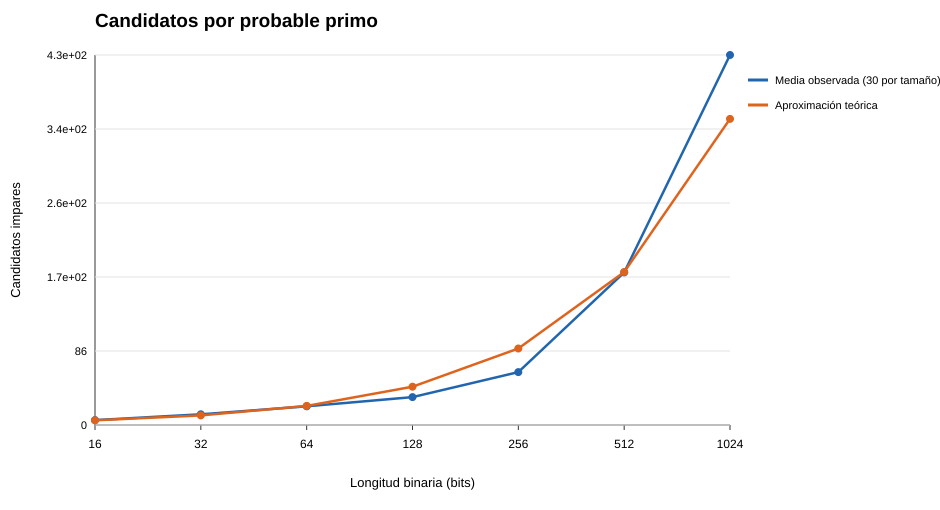

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Candidatos por probable primo</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="200.83333333333331" y1="425" x2="200.83333333333331" y2="430" stroke="#333"/><text x="200.83333333333331" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="306.66666666666663" y1="425" x2="306.66666666666663" y2="430" stroke="#333"/><text x="306.66666666666663" y="448" text-anchor="middle" font-size="12" font-family="Arial">64</text><line x1="412.5" y1="425" x2="412.5" y2="430" stroke="#333"/><text x="412.5" y="448" text-anchor="middle" font-size="12"

In [19]:
line_chart("fig3_candidatos_vs_bits.svg", "Candidatos por probable primo", list(SIZES), [
    ("Media observada (30 por tamaño)", [(r["bits"], r["candidatos_media"]) for r in generation]),
    ("Aproximación teórica", [(r["bits"], r["candidatos_estimados"]) for r in generation]),
], "Longitud binaria (bits)", "Candidatos impares")

### Comparación: Fermat, Miller–Rabin y división de prueba
Las 20 bases de cada entrada se fijan antes de medir. Datos completos y tiempos mínimo/mediano/máximo, en memoria.

In [20]:
def compare_methods(primes_by_bits):
    rng = make_rng(SEED_BENCHMARK)
    inputs = [case for bits in SIZES for case in benchmark_inputs(
        bits, primes_by_bits[bits], rng, BENCHMARK_PAIRS)]
    # CSV de las bases realmente usadas: la semilla sola no documenta qué
    # testigos concretos recibió cada método ni facilita auditar una fila.
    write_csv("entradas_y_bases.csv", (
        {"seed": SEED_BENCHMARK, "bits": case["bits"], "indice": case["indice"],
         "tipo_entrada": case["tipo"], "n": case["n"],
         "bases_20": json.dumps(case["bases"])} for case in inputs))
    rows = []
    for case in inputs:
        bits, n, kind, bases = (case["bits"], case["n"],
                                case["tipo"], case["bases"])
        methods = [("fermat", r) for r in ROUNDS] + [("miller_rabin", r) for r in ROUNDS]
        if bits <= TRIAL_MAX_BITS:
            methods.append(("division_prueba", 0))
        for method, rounds in methods:
            if method == "division_prueba":
                run = lambda: trial_division_with_count(n)
                result, divisions = run()
                outcome = "primo" if result else "compuesto"
                actual_rounds = squares = chain_squares = 0
            elif method == "fermat":
                run = lambda: fermat_test(n, bases[:rounds])
                detail = run()
                outcome = detail["resultado"]
                actual_rounds = detail["rondas_ejecutadas"]
                squares, chain_squares, divisions = detail["cuadrados_modulares"], 0, 0
            else:
                run = lambda: primality_report(n, rounds, bases=bases, presieve=False)
                detail = run()
                outcome = detail["resultado"]
                actual_rounds = detail["rondas_ejecutadas"]
                squares, chain_squares, divisions = (detail["cuadrados_modulares"],
                                                     detail["cuadrados_cadena"], 0)
            min_ns, median_ns, max_ns = measure(run)
            is_composite = kind == "compuesto_construido"
            rows.append({"seed": SEED_BENCHMARK, "bits": bits, "indice": case["indice"],
                         "tipo_entrada": kind, "n": n, "metodo": method,
                         "rondas_solicitadas": rounds, "rondas_ejecutadas": actual_rounds,
                         "cuadrados_modulares": squares, "cuadrados_cadena": chain_squares,
                         "divisiones": divisions, "resultado": outcome,
                         "falso_positivo_compuesto": is_composite and outcome not in ("compuesto",),
                         "repeticiones": REPETITIONS, "min_ns": min_ns,
                         "mediana_ns": median_ns, "max_ns": max_ns})
    write_csv("comparacion_metodos.csv", rows)
    summary = []
    for bits in SIZES:
        for kind in ("primo_verificado" if bits <= 32 else "probable_primo",
                     "compuesto_construido"):
            for method, rounds in [("fermat", r) for r in ROUNDS] + [
                    ("miller_rabin", r) for r in ROUNDS] + (
                        [("division_prueba", 0)] if bits <= 32 else []):
                subset = [r for r in rows if (r["bits"], r["tipo_entrada"],
                           r["metodo"], r["rondas_solicitadas"]) ==
                          (bits, kind, method, rounds)]
                summary.append({"seed": SEED_BENCHMARK, "bits": bits,
                                "tipo_entrada": kind, "metodo": method, "rondas": rounds,
                                "entradas": len(subset),
                                "tiempo_mediano_us": round(median(r["mediana_ns"]
                                                            for r in subset) / 1000, 3),
                                "rondas_mediana": median(r["rondas_ejecutadas"] for r in subset),
                                "cuadrados_mediana": median(r["cuadrados_modulares"] for r in subset),
                                "falsos_positivos": sum(r["falso_positivo_compuesto"]
                                                        for r in subset)})
        print(f"Comparación {bits:4d} bits: 16 entradas, métodos Fermat/MR "
              f"(1,5,10,20 rondas){' y división' if bits <= 32 else ''}")
    write_csv("resumen_comparacion.csv", summary)
    return rows, summary

comparison_rows, comparison = compare_methods(primes_by_bits)
show_table([row for row in comparison if row["tipo_entrada"] != "compuesto_construido"],
           columns=["bits", "metodo", "rondas", "tiempo_mediano_us", "rondas_mediana",
                    "cuadrados_mediana", "falsos_positivos"], limit=70,
           title="Mismas entradas; Fermat, MR y división hasta 32 bits")
show_table([row for row in comparison_rows if row["bits"] == 16 and row["indice"] == 0
           and row["tipo_entrada"] == "primo_verificado"],
           columns=["metodo", "rondas_solicitadas", "rondas_ejecutadas",
                    "cuadrados_modulares", "min_ns", "mediana_ns", "max_ns", "resultado"],
           title="Ejemplo: siete mediciones sobre la misma entrada")

Comparación   16 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas) y división
Comparación   32 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas) y división
Comparación   64 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  128 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  256 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación  512 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)
Comparación 1024 bits: 16 entradas, métodos Fermat/MR (1,5,10,20 rondas)


bits,metodo,rondas,tiempo_mediano_us,rondas_mediana,cuadrados_mediana,falsos_positivos
16,fermat,1,11.2,1.0,15.0,0
16,fermat,5,48.35,5.0,75.0,0
16,fermat,10,94.1,10.0,150.0,0
16,fermat,20,187.45,20.0,300.0,0
16,miller_rabin,1,15.0,1.0,14.0,0
16,miller_rabin,5,61.3,5.0,70.0,0
16,miller_rabin,10,121.8,10.0,140.0,0
16,miller_rabin,20,229.5,20.0,280.0,0
16,division_prueba,0,17.6,0.0,0.0,0
32,fermat,1,30.1,1.0,31.0,0


metodo,rondas_solicitadas,rondas_ejecutadas,cuadrados_modulares,min_ns,mediana_ns,max_ns,resultado
fermat,1,1,15,10500,10800,35300,pasa_fermat
fermat,5,5,75,46100,47300,52300,pasa_fermat
fermat,10,10,150,81900,93500,239900,pasa_fermat
fermat,20,20,300,135600,175100,234100,pasa_fermat
miller_rabin,1,1,14,13400,15800,23700,probable_primo
miller_rabin,5,5,70,55900,66100,69800,probable_primo
miller_rabin,10,10,140,105800,123800,136400,probable_primo
miller_rabin,20,20,280,224300,242700,288300,probable_primo
division_prueba,0,0,0,18200,18500,20600,primo


### Figura 1: tiempo por longitud binaria

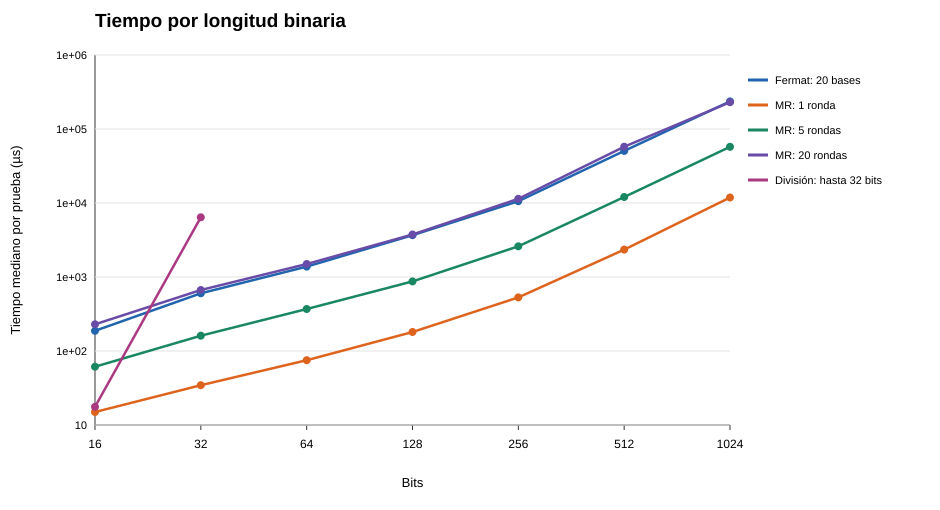

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Tiempo por longitud binaria</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="200.83333333333331" y1="425" x2="200.83333333333331" y2="430" stroke="#333"/><text x="200.83333333333331" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="306.66666666666663" y1="425" x2="306.66666666666663" y2="430" stroke="#333"/><text x="306.66666666666663" y="448" text-anchor="middle" font-size="12" font-family="Arial">64</text><line x1="412.5" y1="425" x2="412.5" y2="430" stroke="#333"/><text x="412.5" y="448" text-anchor="middle" font-size="12" f

In [21]:
primes = {"primo_verificado", "probable_primo"}
lines = []
for method, rounds, label in (("fermat", 20, "Fermat: 20 bases"),
                              ("miller_rabin", 1, "MR: 1 ronda"),
                              ("miller_rabin", 5, "MR: 5 rondas"),
                              ("miller_rabin", 20, "MR: 20 rondas"),
                              ("division_prueba", 0, "División: hasta 32 bits")):
    points = [(row["bits"], row["tiempo_mediano_us"]) for row in comparison
              if row["tipo_entrada"] in primes and row["metodo"] == method and row["rondas"] == rounds]
    lines.append((label, points))
line_chart("fig1_tiempo_vs_bits.svg", "Tiempo por longitud binaria", list(SIZES),
           lines, "Bits", "Tiempo mediano por prueba (µs)", log_y=True)

### Figura 2: rondas y cuadrados modulares

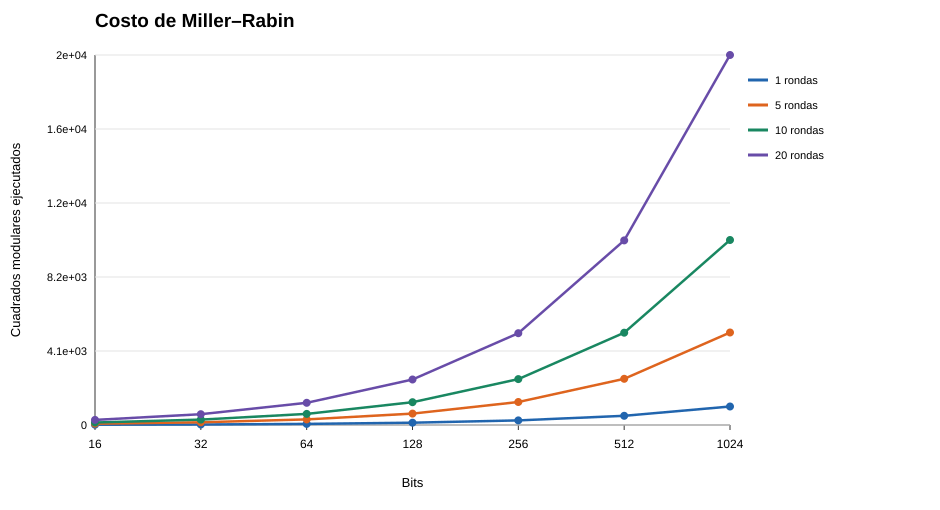

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Costo de Miller–Rabin</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">16</text><line x1="200.83333333333331" y1="425" x2="200.83333333333331" y2="430" stroke="#333"/><text x="200.83333333333331" y="448" text-anchor="middle" font-size="12" font-family="Arial">32</text><line x1="306.66666666666663" y1="425" x2="306.66666666666663" y2="430" stroke="#333"/><text x="306.66666666666663" y="448" text-anchor="middle" font-size="12" font-family="Arial">64</text><line x1="412.5" y1="425" x2="412.5" y2="430" stroke="#333"/><text x="412.5" y="448" text-anchor="middle" font-size="12" font-fa

In [22]:
line_chart("fig2_cuadrados_vs_bits.svg", "Costo de Miller–Rabin", list(SIZES),
    [(f"{r} rondas", [(row["bits"], row["cuadrados_mediana"])
                      for row in comparison if row["metodo"] == "miller_rabin"
                      and row["rondas"] == r and row["tipo_entrada"] in primes])
     for r in ROUNDS], "Bits", "Cuadrados modulares ejecutados")

### Testigos, mentirosos fuertes y frecuencia de error
La tabla distingue frecuencia observada, probabilidad exacta para cada compuesto y cota universal.

In [23]:
def liars_and_error():
    base_rows, summary = [], []
    chosen = set(range(5, 200, 2)) | {221, 341, 561}
    for n in sorted(chosen):
        if trial_division(n):
            continue
        result = classify_bases(n)
        liars = set(result["mentirosos_fuertes"])
        summary.append({"n": n, "bases_validas": n - 3,
                        "testigos": len(result["testigos"]),
                        "mentirosos_fuertes": len(liars),
                        "fraccion_mentirosos": round(result["fraccion_mentirosos"], 8),
                        "cota_un_cuarto": 0.25})
        for a in range(2, n - 1):
            base_rows.append({"n": n, "a": a, "clase":
                              "mentiroso_fuerte" if a in liars else "testigo"})
    write_csv("clasificacion_bases.csv", base_rows)
    write_csv("resumen_testigos_mentirosos.csv", summary)
    assert all(row["fraccion_mentirosos"] <= 0.25 for row in summary)

    # Simulación de bases uniformes independientes con reemplazo. El valor
    # exacto (p_n)^r se obtiene de la clasificación exhaustiva, sin simular MR.
    rng = make_rng(SEED_LIARS)
    rate_rows = []
    trials = 3000
    for n in (25, 91, 121, 341, 561):
        liar_set = set(classify_bases(n)["mentirosos_fuertes"])
        p = len(liar_set) / (n - 3)
        for rounds in ROUNDS:
            accepted = 0
            for _ in range(trials):
                accepted += all(rng.randrange(2, n - 1) in liar_set
                                for _ in range(rounds))
            rate_rows.append({"seed": SEED_LIARS, "n": n, "rondas": rounds,
                              "muestras": trials, "compuestos_aceptados": accepted,
                              "tasa_empirica": round(accepted / trials, 8),
                              "tasa_exacta_bases_aleatorias": p**rounds,
                              "cota_teorica": 4.0**-rounds})
    write_csv("tasa_error_empirica.csv", rate_rows)
    return summary, rate_rows

liars, rates = liars_and_error()
show_table([row for row in liars if row["n"] in (25, 91, 121, 221, 341, 561)],
           title="Testigos y mentirosos fuertes por compuesto")
show_table([row for row in rates if row["n"] in (25, 341, 561)],
           title="3000 ensayos por combinación; cero observado no es probabilidad cero")

n,bases_validas,testigos,mentirosos_fuertes,fraccion_mentirosos,cota_un_cuarto
25,22,20,2,0.09090909,0.25
91,88,72,16,0.18181818,0.25
121,118,110,8,0.06779661,0.25
221,218,214,4,0.01834862,0.25
341,338,290,48,0.14201183,0.25
561,558,550,8,0.01433692,0.25


seed,n,rondas,muestras,compuestos_aceptados,tasa_empirica,tasa_exacta_bases_aleatorias,cota_teorica
20260703,25,1,3000,281,0.09366667,0.09090909090909091,0.25
20260703,25,5,3000,0,0.0,6.209213230591552e-06,0.0009765625
20260703,25,10,3000,0,0.0,3.855432894295319e-11,9.5367431640625e-07
20260703,25,20,3000,0,0.0,1.4864362802414377e-21,9.094947017729282e-13
20260703,341,1,3000,413,0.13766667,0.14201183431952663,0.25
20260703,341,5,3000,0,0.0,5.775940163861411e-05,0.0009765625
20260703,341,10,3000,0,0.0,3.3361484776507386e-09,9.5367431640625e-07
20260703,341,20,3000,0,0.0,1.1129886664931341e-17,9.094947017729282e-13
20260703,561,1,3000,38,0.01266667,0.014336917562724014,0.25
20260703,561,5,3000,0,0.0,6.057298002246945e-10,0.0009765625


### Figura 4: error observado y cota teórica
Cero aceptaciones observadas se indica debajo; no se coloca en el eje logarítmico.

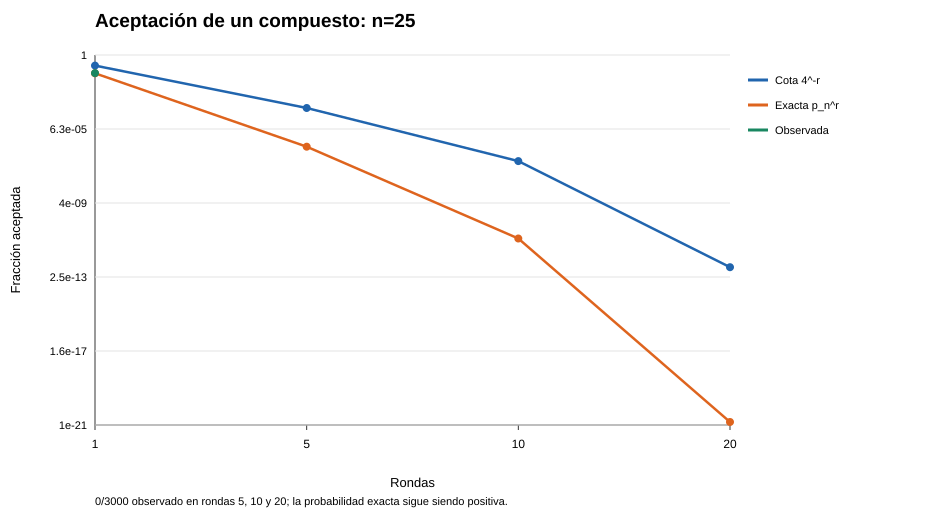

'<svg xmlns="http://www.w3.org/2000/svg" width="940" height="510" viewBox="0 0 940 510"><rect width="100%" height="100%" fill="white"/><text x="95" y="27" font-size="19" font-family="Arial" font-weight="bold">Aceptación de un compuesto: n=25</text><line x1="95" y1="425" x2="730" y2="425" stroke="#333"/><line x1="95" y1="55" x2="95" y2="425" stroke="#333"/><line x1="95.0" y1="425" x2="95.0" y2="430" stroke="#333"/><text x="95.0" y="448" text-anchor="middle" font-size="12" font-family="Arial">1</text><line x1="306.66666666666663" y1="425" x2="306.66666666666663" y2="430" stroke="#333"/><text x="306.66666666666663" y="448" text-anchor="middle" font-size="12" font-family="Arial">5</text><line x1="518.3333333333333" y1="425" x2="518.3333333333333" y2="430" stroke="#333"/><text x="518.3333333333333" y="448" text-anchor="middle" font-size="12" font-family="Arial">10</text><line x1="730.0" y1="425" x2="730.0" y2="430" stroke="#333"/><text x="730.0" y="448" text-anchor="middle" font-size="12" f

In [24]:
selected = [row for row in rates if row["n"] == 25]
line_chart("fig4_error_empirico.svg", "Aceptación de un compuesto: n=25", list(ROUNDS), [
    ("Cota 4^-r", [(row["rondas"], row["cota_teorica"]) for row in selected]),
    ("Exacta p_n^r", [(row["rondas"], row["tasa_exacta_bases_aleatorias"]) for row in selected]),
    ("Observada", [(row["rondas"], row["tasa_empirica"]) for row in selected
                  if row["tasa_empirica"] > 0]),
], "Rondas", "Fracción aceptada", log_y=True,
   note="0/3000 observado en rondas 5, 10 y 20; la probabilidad exacta sigue siendo positiva.")

### Auditoría final de datos en memoria
Verifica casos, trazas, 210 números generados, 928 comparaciones, bases, cotas y las cuatro figuras.

In [25]:
assert len(DATASETS) == 10 and len(CHARTS) == 4
assert len(DATASETS["generacion_210_probables_primos.csv"]) == 210
assert len(DATASETS["comparacion_metodos.csv"]) == 928
assert len(DATASETS["clasificacion_bases.csv"]) == 6726
assert len(DATASETS["entradas_y_bases.csv"]) == 112
assert all(sum(row["bits"] == bits for row in DATASETS["generacion_210_probables_primos.csv"]) == 30
           for bits in SIZES)
expected = {221: [128, 30], 341: [32, 1], 561: [263, 166, 67, 1]}
assert all(json.loads(next(row["residuos"] for row in DATASETS["trazas_miller_rabin.csv"]
                           if row["n"] == n and row["a"] == 2)) == values
           for n, values in expected.items())
assert all(0 <= row["tasa_exacta_bases_aleatorias"] <= row["cota_teorica"]
           for row in DATASETS["tasa_error_empirica.csv"])
assert next(row["tasa_exacta_bases_aleatorias"] for row in DATASETS["tasa_error_empirica.csv"]
            if row["n"] == 25 and row["rondas"] == 20) > 0
print("Auditoría correcta: 10 CSV en memoria, 4 gráficos visibles, 210 candidatos aceptados,"
      " 928 comparaciones y 6726 bases clasificadas.")

Auditoría correcta: 10 CSV en memoria, 4 gráficos visibles, 210 candidatos aceptados, 928 comparaciones y 6726 bases clasificadas.


## 12. Análisis (respuestas breves)
1. Todo compuesto $n=ab$ tiene un factor $\leq\sqrt n$: si ambos fueran mayores, su producto excedería $n$.
2. En $L$ bits, $\sqrt n=\Theta(2^{L/2})$, exponencial en $L$.
3. Si Fermat falla, $n$ es compuesto; si pasa, $n$ puede ser pseudoprimo.
4. Un pseudoprimo pasa una base coprima; Carmichael pasa todas las coprimas.
5. La descomposición $n-1=2^sd$ permite buscar $-1$ en la cadena de cuadrados.
6. Una raíz no trivial de $1$ módulo $n$ implica composición.
7. Testigo: rechaza un compuesto; mentiroso fuerte: lo acepta.
8. Un primo nunca es rechazado por una base válida: error unilateral.
9. $4^{-r}$ requiere bases uniformes independientes para compuesto impar.
10. Una semilla fija permite reconstruir claves; para ellas, usar fuente segura.
11. El precribado elimina factores pequeños antes de rondas costosas.
12. Cero errores en una muestra finita no prueba probabilidad cero.

## 13. Entrega opcional sin crear archivos durante el cálculo
El informe PDF sigue siendo un producto aparte. Aquí se ofrece un **enlace de descarga** con los diez CSV y cuatro gráficos SVG producidos **en memoria**. Descargar el ZIP es opcional: los resultados y figuras ya aparecen bajo sus celdas y quedan incrustados al guardar el `.ipynb`.

In [26]:
buffer = io.BytesIO()
with ZipFile(buffer, "w", ZIP_DEFLATED) as zf:
    for name, rows in DATASETS.items():
        text = io.StringIO(newline="")
        writer = csv.DictWriter(text, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
        zf.writestr("results/" + name, text.getvalue().encode("utf-8"))
    for name, svg in CHARTS.items():
        zf.writestr("figures/" + name, svg.encode("utf-8"))
payload = b64encode(buffer.getvalue()).decode("ascii")
display(HTML('<a download="lab07_resultados.zip" href="data:application/zip;base64,'
             + payload + '">Descargar evidencias (ZIP: 10 CSV y 4 gráficos SVG)</a>'))
print("Evidencias listas en esta celda; no se escribió ningún archivo en el entorno.")

Evidencias listas en esta celda; no se escribió ningún archivo en el entorno.
